# Color-Invariant Saree Design Recognition

## Goal
Learn an embedding in which:
- images of the same saree design are close, even across different colorways;
- images of different designs are far apart, even if their colours look similar.

## Output
1. Identification: retrieve the top-k closest gallery designs for a query.
2. Verification: decide whether two images share the same design.
3. Evaluation: Recall@K, mAP, ROC-AUC, EER, parameter count, and latency.

## Core idea
A pretrained EfficientNet-B0 backbone creates a 256-dimensional L2-normalized embedding.
Training uses supervised contrastive loss plus a cross-entropy classification objective.
Colour-focused augmentation (grayscale, hue/saturation changes, colour jitter) discourages
the model from treating colour as the identity of a saree.

In [1]:
import shutil
import os

source = "/kaggle/input/indian-saree-patterns"
destination = "/content/indian-saree-patterns"

shutil.copytree(
    source,
    destination,
    dirs_exist_ok=True
)

print("Dataset copied to:", destination)
print("Exists:", os.path.exists(destination))

Dataset copied to: /content/indian-saree-patterns
Exists: True


In [2]:
# Kaggle dependencies (run only if a package is missing)
# !pip install -q timm torchmetrics

import os
import re
import gc
import time
import math
import random
import warnings
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score,
    confusion_matrix, classification_report
)
from sklearn.preprocessing import normalize

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm

warnings.filterwarnings("ignore")

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything()

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cpu
PyTorch: 2.11.0+cpu


In [3]:
DATA_ROOTS = [
    Path("/kaggle/input/indian-saree-patterns"),
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

for root in DATA_ROOTS:
    print(f"{root} -> exists: {root.exists()}")
    if root.exists():
        print("Top-level entries:", [p.name for p in list(root.iterdir())[:10]])

/kaggle/input/indian-saree-patterns -> exists: True
Top-level entries: ['README.dataset.txt', 'README.roboflow.txt', 'valid', 'test', 'train']


In [4]:
def infer_pattern_class(image_path: Path, root: Path) -> str:
    """
    Expected structure:
    root/train/Banarasi/image.jpg
    root/valid/Ikat/image.jpg
    root/test/Pichwai/image.jpg

    relative.parts becomes:
    ('train', 'Banarasi', 'image.jpg')

    So:
    relative.parts[0] = supplied split
    relative.parts[1] = pattern class
    """
    relative = image_path.relative_to(root)

    if len(relative.parts) < 3:
        raise ValueError(f"Unexpected image path structure: {image_path}")

    return relative.parts[1]


def infer_source_split(image_path: Path, root: Path) -> str:
    """Returns train, valid, or test."""
    relative = image_path.relative_to(root)
    return relative.parts[0]


def build_metadata(roots):
    rows = []

    for root in roots:
        if not root.exists():
            continue

        image_paths = [
            p for p in root.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        for path in tqdm(image_paths, desc=f"Scanning {root.name}"):
            try:
                with Image.open(path) as image:
                    width, height = image.size
                    image.verify()
            except Exception:
                continue

            rows.append({
                "path": str(path),
                "source": root.name,
                "split": infer_source_split(path, root),
                "pattern_class": infer_pattern_class(path, root),
                "width": width,
                "height": height
            })

    df = pd.DataFrame(rows)

    if len(df) == 0:
        raise RuntimeError(
            "No readable images found. Check DATA_ROOTS and file extensions."
        )

    return df


df = build_metadata(DATA_ROOTS)

print("Total readable images:", len(df))
print("\nImages per supplied split:")
display(df["split"].value_counts())

print("\nImages per class:")
display(pd.crosstab(df["split"], df["pattern_class"]))

display(df.head())
df.to_csv("all_metadata.csv", index=False)

Scanning indian-saree-patterns:   0%|          | 0/1468 [00:00<?, ?it/s]

Total readable images: 1468

Images per supplied split:


,count
split,
train,1293
valid,115
test,60



Images per class:


pattern_class,Banarasi,Bandhani,Ikat,Pichwai
split,,,,
test,14,15,13,18
train,432,279,303,279
valid,43,22,26,24


,path,source,split,pattern_class,width,height
0,/kaggle/input/indian-saree-patterns/train/Bana...,indian-saree-patterns,train,Banarasi,640,640
1,/kaggle/input/indian-saree-patterns/train/Bana...,indian-saree-patterns,train,Banarasi,640,640
2,/kaggle/input/indian-saree-patterns/train/Bana...,indian-saree-patterns,train,Banarasi,640,640
3,/kaggle/input/indian-saree-patterns/train/Bana...,indian-saree-patterns,train,Banarasi,640,640
4,/kaggle/input/indian-saree-patterns/train/Bana...,indian-saree-patterns,train,Banarasi,640,640


In [5]:
class_to_idx = {
    class_name: index
    for index, class_name in enumerate(sorted(df["pattern_class"].unique()))
}

df["label"] = df["pattern_class"].map(class_to_idx)

train_df = df[df["split"] == "train"].copy().reset_index(drop=True)
val_df = df[df["split"] == "valid"].copy().reset_index(drop=True)
test_df = df[df["split"] == "test"].copy().reset_index(drop=True)

print("Class mapping:", class_to_idx)

for name, split_df in {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df
}.items():
    print(
        f"{name:12s} | images={len(split_df):5d} | "
        f"classes={split_df['label'].nunique()}"
    )

assert len(train_df) > 0
assert len(val_df) > 0
assert len(test_df) > 0
assert set(train_df["label"]) == set(val_df["label"]) == set(test_df["label"])

Class mapping: {'Banarasi': 0, 'Bandhani': 1, 'Ikat': 2, 'Pichwai': 3}
Train        | images= 1293 | classes=4
Validation   | images=  115 | classes=4
Test         | images=   60 | classes=4


In [6]:
IMAGE_SIZE = 224
BATCH_SIZE = 16   # 32
NUM_WORKERS =  0   # 2

train_transform = T.Compose([
    T.RandomResizedCrop(
        IMAGE_SIZE,
        scale=(0.70, 1.0),
        ratio=(0.75, 1.33)
    ),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomApply([
        T.ColorJitter(
            brightness=0.35,
            contrast=0.35,
            saturation=0.75,
            hue=0.15
        )
    ], p=0.90),
    T.RandomGrayscale(p=0.35),
    T.RandomApply([
        T.GaussianBlur(kernel_size=3)
    ], p=0.15),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    T.RandomErasing(
        p=0.15,
        scale=(0.02, 0.10),
        ratio=(0.3, 3.3)
    )
])

eval_transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(IMAGE_SIZE),
    T.ToTensor(),
    T.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class SareeDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")
        image = self.transform(image)

        return {
            "image": image,
            "label": torch.tensor(int(row["label"]), dtype=torch.long),
            "path": row["path"]
        }


train_ds = SareeDataset(train_df, train_transform)
val_ds = SareeDataset(val_df, eval_transform)
test_ds = SareeDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    # pin_memory=True,
    pin_memory=(DEVICE.type == "cuda"),
    drop_last=False
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    # pin_memory=True
    pin_memory=(DEVICE.type == "cuda"),
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    # pin_memory=True
    pin_memory=(DEVICE.type == "cuda"),
)

print("NUM_WORKERS:", NUM_WORKERS)
print("BATCH_SIZE:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print(f"Train images: {len(train_ds)}")
print(f"Validation images: {len(val_ds)}")
print(f"Test images: {len(test_ds)}")
print(f"Training batches: {len(train_loader)}")

sample_batch = next(iter(train_loader))
print("Batch image shape:", sample_batch["image"].shape)
print("Batch labels shape:", sample_batch["label"].shape)

NUM_WORKERS: 0
BATCH_SIZE: 16
Train batches: 81
Validation batches: 8
Test batches: 4
Train images: 1293
Validation images: 115
Test images: 60
Training batches: 81
Batch image shape: torch.Size([16, 3, 224, 224])
Batch labels shape: torch.Size([16])


## Model

In [7]:
EMBED_DIM = 256
NUM_CLASSES = len(class_to_idx)

class SareeEmbeddingModel(nn.Module):
    def __init__(self, num_classes, embedding_dim=EMBED_DIM):
        super().__init__()

        self.backbone = timm.create_model(
            "efficientnet_b0",
            pretrained=True,
            num_classes=0,
            global_pool="avg"
        )

        backbone_dim = self.backbone.num_features

        self.embedding_head = nn.Sequential(
            nn.Linear(backbone_dim, embedding_dim),
            nn.BatchNorm1d(embedding_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(0.15),
            nn.Linear(embedding_dim, embedding_dim)
        )

        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, x):
        features = self.backbone(x)

        embedding = self.embedding_head(features)
        embedding = F.normalize(embedding, p=2, dim=1)

        logits = self.classifier(embedding)

        return embedding, logits


model = SareeEmbeddingModel(
    num_classes=NUM_CLASSES,
    embedding_dim=EMBED_DIM
).to(DEVICE)

parameter_count = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print(f"Number of classes: {NUM_CLASSES}")
print(f"Embedding dimension: {EMBED_DIM}")
print(f"Trainable parameters: {parameter_count / 1e6:.2f} million")

Number of classes: 4
Embedding dimension: 256
Trainable parameters: 4.40 million


## Loss and Optimizer

In [8]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.10)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)

EPOCHS = 6 # 10

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)

scaler = torch.cuda.amp.GradScaler(
    enabled=(DEVICE.type == "cuda")
)

## Training and evaluation functions

In [9]:
def train_one_epoch(model, loader, optimizer, criterion, scaler):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(loader, desc="Training", leave=False)

    for batch in progress_bar:
        images = batch["image"].to(DEVICE, non_blocking=True)
        labels = batch["label"].to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=(DEVICE.type == "cuda")):
            _, logits = model(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}",
            accuracy=f"{correct / total:.4f}"
        )

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate_classifier(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    all_labels = []
    all_predictions = []
    all_embeddings = []
    all_paths = []

    for batch in tqdm(loader, desc="Evaluating", leave=False):
        images = batch["image"].to(DEVICE, non_blocking=True)
        labels = batch["label"].to(DEVICE, non_blocking=True)

        embeddings, logits = model(images)
        loss = criterion(logits, labels)

        predictions = logits.argmax(dim=1)

        total_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_embeddings.append(embeddings.cpu().numpy())
        all_paths.extend(batch["path"])

    return {
        "loss": total_loss / total,
        "accuracy": correct / total,
        "labels": np.array(all_labels),
        "predictions": np.array(all_predictions),
        "embeddings": np.concatenate(all_embeddings, axis=0),
        "paths": all_paths
    }

## Train model

In [10]:
# best_val_accuracy = -1.0
# history = []

# for epoch in range(1, EPOCHS + 1):
#     train_loss, train_accuracy = train_one_epoch(
#         model=model,
#         loader=train_loader,
#         optimizer=optimizer,
#         criterion=criterion,
#         scaler=scaler
#     )

#     validation_result = evaluate_classifier(
#         model=model,
#         loader=val_loader,
#         criterion=criterion
#     )

#     scheduler.step()

#     row = {
#         "epoch": epoch,
#         "train_loss": train_loss,
#         "train_accuracy": train_accuracy,
#         "val_loss": validation_result["loss"],
#         "val_accuracy": validation_result["accuracy"],
#         "learning_rate": optimizer.param_groups[0]["lr"]
#     }

#     history.append(row)

#     print(
#         f"Epoch {epoch:02d}/{EPOCHS} | "
#         f"Train loss: {train_loss:.4f} | "
#         f"Train accuracy: {train_accuracy:.4f} | "
#         f"Validation loss: {validation_result['loss']:.4f} | "
#         f"Validation accuracy: {validation_result['accuracy']:.4f}"
#     )

#     if validation_result["accuracy"] > best_val_accuracy:
#         best_val_accuracy = validation_result["accuracy"]

#         torch.save(
#             {
#                 "epoch": epoch,
#                 "model_state_dict": model.state_dict(),
#                 "best_val_accuracy": best_val_accuracy,
#                 "class_to_idx": class_to_idx,
#                 "embedding_dim": EMBED_DIM
#             },
#             "best_saree_pattern_model.pt"
#         )

#         print("Best model saved.")

# history_df = pd.DataFrame(history)
# history_df.to_csv("training_history.csv", index=False)

# display(history_df)

EPOCHS = 6
PATIENCE = 2

best_val_accuracy = -1.0
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):

    train_loss, train_accuracy = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        scaler=scaler
    )

    validation_result = evaluate_classifier(
        model=model,
        loader=val_loader,
        criterion=criterion
    )

    scheduler.step()

    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": validation_result["loss"],
        "val_accuracy": validation_result["accuracy"],
        "learning_rate": optimizer.param_groups[0]["lr"]
    }

    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.4f} | "
        f"Validation loss: {validation_result['loss']:.4f} | "
        f"Validation accuracy: {validation_result['accuracy']:.4f}"
    )

    if validation_result["accuracy"] > best_val_accuracy:
        best_val_accuracy = validation_result["accuracy"]
        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "best_val_accuracy": best_val_accuracy,
                "class_to_idx": class_to_idx,
                "embedding_dim": EMBED_DIM
            },
            "best_saree_pattern_model.pt"
        )

        print(
            f"Best model saved with validation accuracy: "
            f"{best_val_accuracy:.4f}"
        )

    else:
        epochs_without_improvement += 1

        print(
            f"No validation improvement for "
            f"{epochs_without_improvement} epoch(s)."
        )

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping activated.")
            break

history_df = pd.DataFrame(history)
history_df.to_csv("training_history.csv", index=False)

display(history_df)

Training:   0%|          | 0/81 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 01/6 | Train loss: 1.1159 | Train accuracy: 0.7943 | Validation loss: 0.8817 | Validation accuracy: 0.9565
Best model saved with validation accuracy: 0.9565


Training:   0%|          | 0/81 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 02/6 | Train loss: 0.8369 | Train accuracy: 0.9288 | Validation loss: 0.7568 | Validation accuracy: 0.9130
No validation improvement for 1 epoch(s).


Training:   0%|          | 0/81 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 03/6 | Train loss: 0.7039 | Train accuracy: 0.9490 | Validation loss: 0.6718 | Validation accuracy: 0.9391
No validation improvement for 2 epoch(s).
Early stopping activated.


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,learning_rate
0,1,1.115946,0.794277,0.881698,0.956522,0.000280
1,2,0.836883,0.928848,0.756817,0.913043,0.000225
2,3,0.703876,0.948956,0.671799,0.939130,0.000150


## Training curves

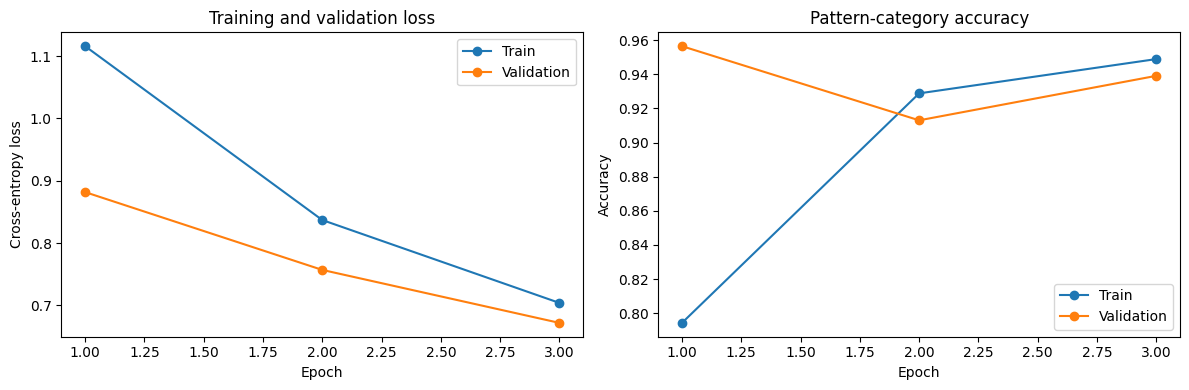

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and validation loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Train"
)
plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Pattern-category accuracy")
plt.legend()

plt.tight_layout()
plt.show()

## Final test evaluation

In [12]:
checkpoint = torch.load(
    "best_saree_pattern_model.pt",
    map_location=DEVICE
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_result = evaluate_classifier(
    model=model,
    loader=test_loader,
    criterion=criterion
)

print(f"Best validation accuracy: {checkpoint['best_val_accuracy']:.4f}")
print(f"Final test loss: {test_result['loss']:.4f}")
print(f"Final test accuracy: {test_result['accuracy']:.4f}")

idx_to_class = {
    index: class_name
    for class_name, index in class_to_idx.items()
}

target_names = [
    idx_to_class[index]
    for index in range(NUM_CLASSES)
]

print("\nClassification report:")
print(
    classification_report(
        test_result["labels"],
        test_result["predictions"],
        target_names=target_names,
        digits=4
    )
)

pd.DataFrame([{
    "test_loss": test_result["loss"],
    "test_accuracy": test_result["accuracy"],
    "best_validation_accuracy": checkpoint["best_val_accuracy"]
}]).to_csv("test_classification_metrics.csv", index=False)

Evaluating:   0%|          | 0/4 [00:00<?, ?it/s]

Best validation accuracy: 0.9565
Final test loss: 0.9242
Final test accuracy: 0.9167

Classification report:
              precision    recall  f1-score   support

    Banarasi     0.8000    0.8571    0.8276        14
    Bandhani     0.8667    0.8667    0.8667        15
        Ikat     1.0000    1.0000    1.0000        13
     Pichwai     1.0000    0.9444    0.9714        18

    accuracy                         0.9167        60
   macro avg     0.9167    0.9171    0.9164        60
weighted avg     0.9200    0.9167    0.9179        60



## Confusion matrix

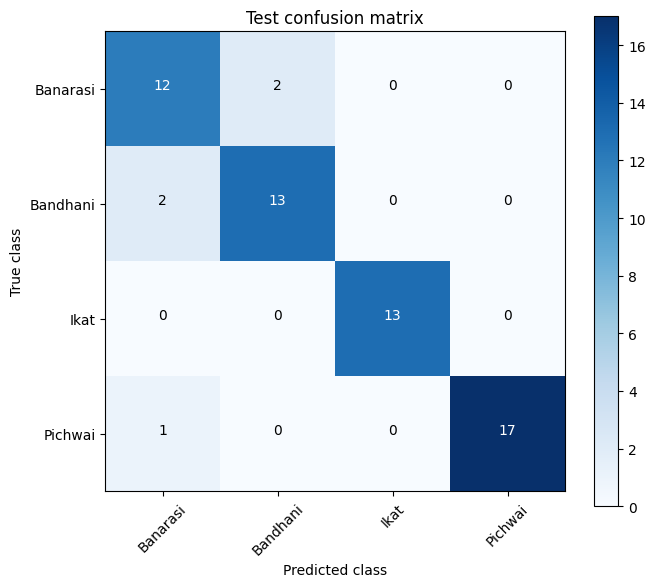

In [13]:
cm = confusion_matrix(
    test_result["labels"],
    test_result["predictions"]
)

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Test confusion matrix")
plt.colorbar()

tick_marks = np.arange(NUM_CLASSES)
plt.xticks(tick_marks, target_names, rotation=45)
plt.yticks(tick_marks, target_names)

threshold_cm = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            horizontalalignment="center",
            color="white" if cm[i, j] > threshold_cm else "black"
        )

plt.ylabel("True class")
plt.xlabel("Predicted class")
plt.tight_layout()
plt.show()

## Create gallery/query split

In [14]:
def create_gallery_query_split(
    dataframe,
    embeddings,
    labels,
    paths,
    gallery_per_class=5,
    seed=SEED
):
    """
    For each pattern class:
    - randomly choose up to 5 images as gallery/reference images
    - use remaining images as queries

    This evaluates category-level retrieval, not exact same-design retrieval.
    """
    rng = np.random.default_rng(seed)

    metadata = dataframe.copy().reset_index(drop=True)
    metadata["embedding_index"] = np.arange(len(metadata))

    gallery_indices = []
    query_indices = []

    for label in sorted(metadata["label"].unique()):
        class_indices = metadata[
            metadata["label"] == label
        ]["embedding_index"].to_numpy()

        rng.shuffle(class_indices)

        gallery_count = min(gallery_per_class, max(1, len(class_indices) // 2))

        gallery_indices.extend(class_indices[:gallery_count])
        query_indices.extend(class_indices[gallery_count:])

    return {
        "gallery_embeddings": embeddings[gallery_indices],
        "gallery_labels": labels[gallery_indices],
        "gallery_paths": [paths[index] for index in gallery_indices],
        "query_embeddings": embeddings[query_indices],
        "query_labels": labels[query_indices],
        "query_paths": [paths[index] for index in query_indices]
    }


retrieval_data = create_gallery_query_split(
    dataframe=test_df,
    embeddings=test_result["embeddings"],
    labels=test_result["labels"],
    paths=test_result["paths"],
    gallery_per_class=5
)

print("Gallery images:", len(retrieval_data["gallery_labels"]))
print("Query images:", len(retrieval_data["query_labels"]))

Gallery images: 20
Query images: 40


## Retrieval metrics

In [15]:
def calculate_retrieval_metrics(
    query_embeddings,
    query_labels,
    gallery_embeddings,
    gallery_labels,
    ks=(1, 3, 5)
):
    similarity_matrix = query_embeddings @ gallery_embeddings.T
    ranked_indices = np.argsort(-similarity_matrix, axis=1)

    metrics = {}

    for k in ks:
        correct = []

        for query_index in range(len(query_labels)):
            top_k_indices = ranked_indices[
                query_index,
                :min(k, len(gallery_labels))
            ]

            top_k_labels = gallery_labels[top_k_indices]

            correct.append(
                query_labels[query_index] in top_k_labels
            )

        metrics[f"Recall@{k}"] = float(np.mean(correct))

    average_precisions = []

    for query_index in range(len(query_labels)):
        ranked_labels = gallery_labels[ranked_indices[query_index]]
        relevance = (ranked_labels == query_labels[query_index]).astype(int)

        precision_values = []
        relevant_seen = 0

        for rank, is_relevant in enumerate(relevance, start=1):
            if is_relevant:
                relevant_seen += 1
                precision_values.append(relevant_seen / rank)

        if len(precision_values) > 0:
            average_precisions.append(np.mean(precision_values))

    metrics["mAP"] = float(np.mean(average_precisions))

    return metrics


retrieval_metrics = calculate_retrieval_metrics(
    query_embeddings=retrieval_data["query_embeddings"],
    query_labels=retrieval_data["query_labels"],
    gallery_embeddings=retrieval_data["gallery_embeddings"],
    gallery_labels=retrieval_data["gallery_labels"]
)

print("Category-level retrieval metrics:")
for metric_name, metric_value in retrieval_metrics.items():
    print(f"{metric_name}: {metric_value:.4f}")

pd.DataFrame([retrieval_metrics]).to_csv(
    "test_retrieval_metrics.csv",
    index=False
)

Category-level retrieval metrics:
Recall@1: 0.8500
Recall@3: 0.9500
Recall@5: 0.9750
mAP: 0.8949


## View retrieval examples

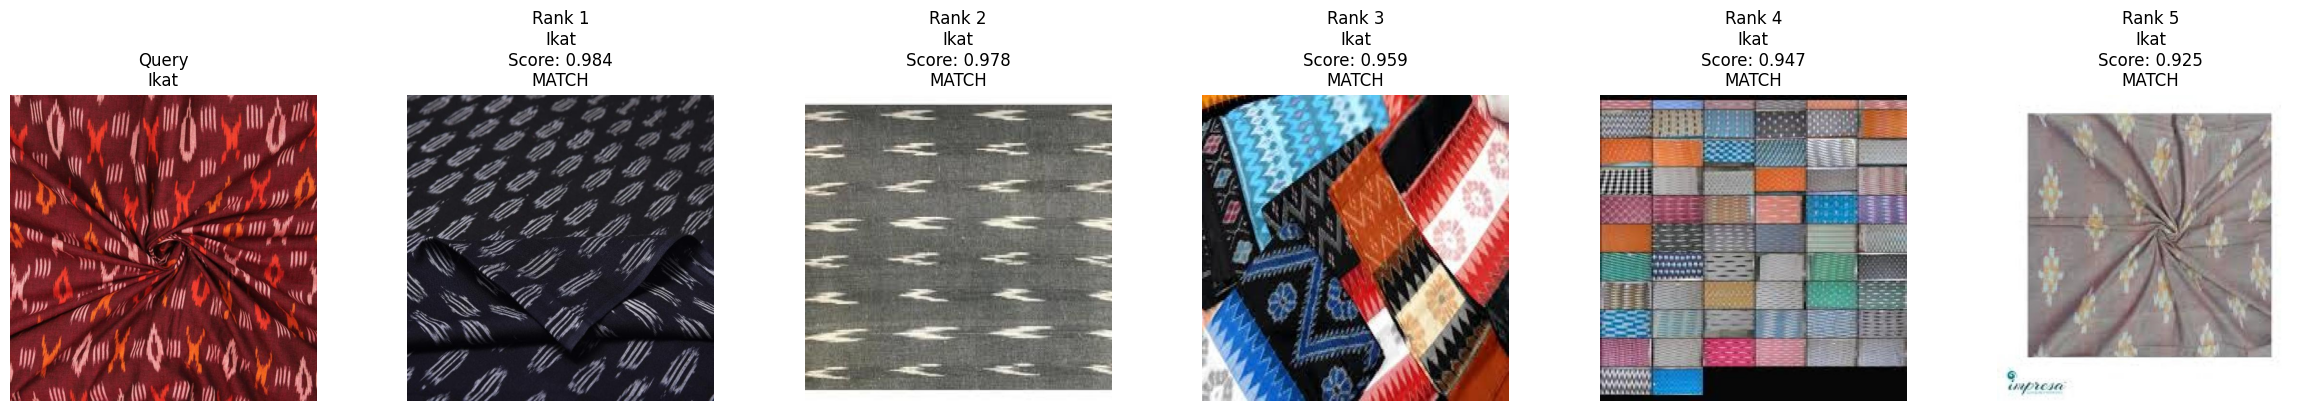

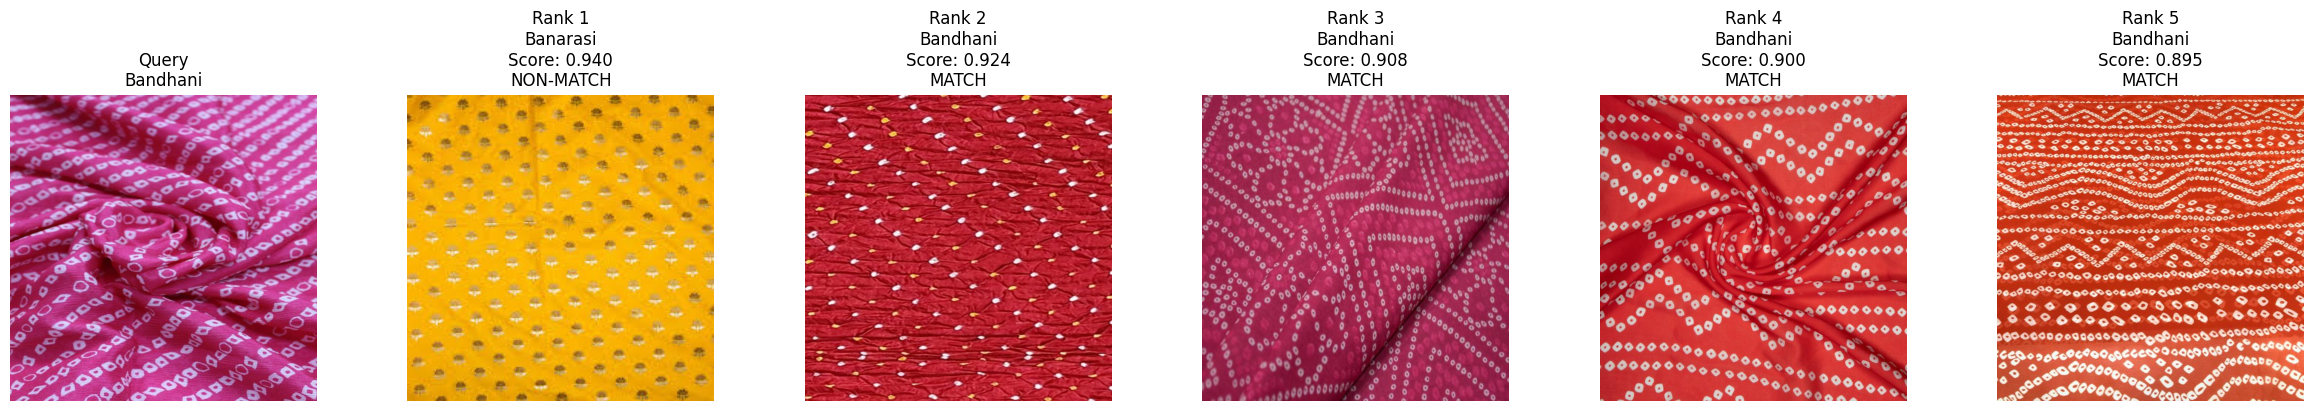

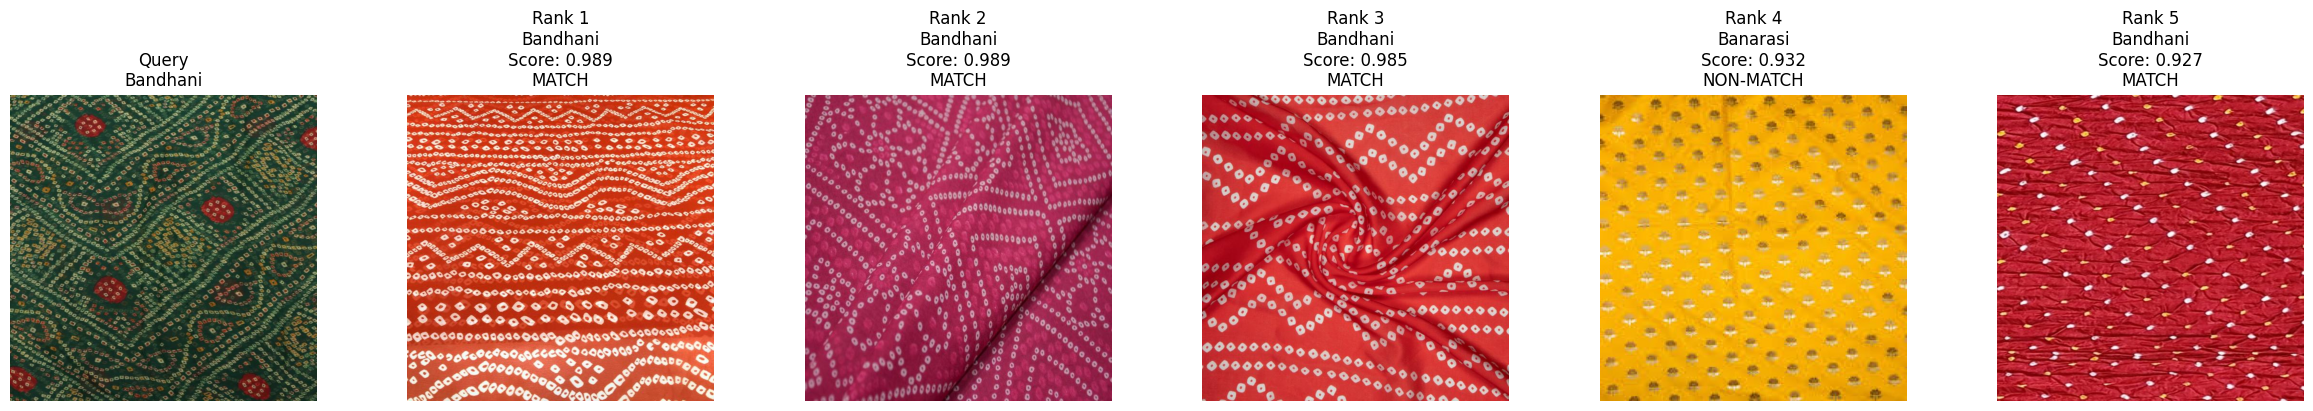

In [16]:
def show_top_k_retrieval(query_index, retrieval_data, k=5):
    query_embedding = retrieval_data["query_embeddings"][query_index]
    query_label = retrieval_data["query_labels"][query_index]
    query_path = retrieval_data["query_paths"][query_index]

    gallery_embeddings = retrieval_data["gallery_embeddings"]
    gallery_labels = retrieval_data["gallery_labels"]
    gallery_paths = retrieval_data["gallery_paths"]

    similarities = gallery_embeddings @ query_embedding
    top_indices = np.argsort(-similarities)[:k]

    fig, axes = plt.subplots(
        1,
        len(top_indices) + 1,
        figsize=(4 * (len(top_indices) + 1), 4)
    )

    axes[0].imshow(Image.open(query_path).convert("RGB"))
    axes[0].set_title(
        f"Query\n{idx_to_class[query_label]}"
    )
    axes[0].axis("off")

    for rank, gallery_index in enumerate(top_indices, start=1):
        gallery_label = gallery_labels[gallery_index]
        correct = gallery_label == query_label

        axes[rank].imshow(
            Image.open(gallery_paths[gallery_index]).convert("RGB")
        )

        axes[rank].set_title(
            f"Rank {rank}\n"
            f"{idx_to_class[gallery_label]}\n"
            f"Score: {similarities[gallery_index]:.3f}\n"
            f"{'MATCH' if correct else 'NON-MATCH'}"
        )

        axes[rank].axis("off")

    plt.tight_layout()
    plt.show()


number_to_show = min(3, len(retrieval_data["query_labels"]))

random_query_indices = np.random.choice(
    len(retrieval_data["query_labels"]),
    size=number_to_show,
    replace=False
)

for query_index in random_query_indices:
    show_top_k_retrieval(
        query_index=query_index,
        retrieval_data=retrieval_data,
        k=5
    )

## Pair verification

Verification ROC-AUC: 0.9502
Verification EER: 0.1050
Similarity threshold: 0.0137


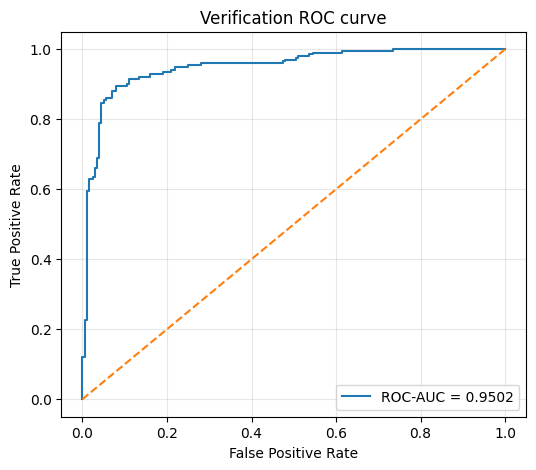

In [17]:
def create_verification_pairs(
    query_embeddings,
    query_labels,
    gallery_embeddings,
    gallery_labels,
    negatives_per_query=5,
    seed=SEED
):
    rng = np.random.default_rng(seed)

    scores = []
    targets = []

    all_gallery_indices = np.arange(len(gallery_labels))

    for query_index, query_label in enumerate(query_labels):
        positive_indices = all_gallery_indices[
            gallery_labels == query_label
        ]

        for gallery_index in positive_indices:
            cosine_similarity = float(
                query_embeddings[query_index] @
                gallery_embeddings[gallery_index]
            )

            scores.append(cosine_similarity)
            targets.append(1)

        negative_indices = all_gallery_indices[
            gallery_labels != query_label
        ]

        selected_negative_indices = rng.choice(
            negative_indices,
            size=min(negatives_per_query, len(negative_indices)),
            replace=False
        )

        for gallery_index in selected_negative_indices:
            cosine_similarity = float(
                query_embeddings[query_index] @
                gallery_embeddings[gallery_index]
            )

            scores.append(cosine_similarity)
            targets.append(0)

    return np.array(scores), np.array(targets)


verification_scores, verification_targets = create_verification_pairs(
    query_embeddings=retrieval_data["query_embeddings"],
    query_labels=retrieval_data["query_labels"],
    gallery_embeddings=retrieval_data["gallery_embeddings"],
    gallery_labels=retrieval_data["gallery_labels"]
)

roc_auc = roc_auc_score(
    verification_targets,
    verification_scores
)

fpr, tpr, thresholds = roc_curve(
    verification_targets,
    verification_scores
)

fnr = 1 - tpr
eer_index = np.nanargmin(np.abs(fpr - fnr))

eer = (fpr[eer_index] + fnr[eer_index]) / 2
verification_threshold = thresholds[eer_index]

print(f"Verification ROC-AUC: {roc_auc:.4f}")
print(f"Verification EER: {eer:.4f}")
print(f"Similarity threshold: {verification_threshold:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Verification ROC curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

pd.DataFrame([{
    "verification_roc_auc": roc_auc,
    "verification_eer": eer,
    "verification_threshold": verification_threshold
}]).to_csv("test_verification_metrics.csv", index=False)

## New image inference

In [18]:
def predict_top_k(
    image_path,
    gallery_embeddings,
    gallery_labels,
    gallery_paths,
    k=5
):
    image = Image.open(image_path).convert("RGB")
    image_tensor = eval_transform(image).unsqueeze(0).to(DEVICE)

    model.eval()

    with torch.no_grad():
        query_embedding, _ = model(image_tensor)

    query_embedding = query_embedding.cpu().numpy()[0]

    similarity_scores = gallery_embeddings @ query_embedding
    top_indices = np.argsort(-similarity_scores)[:k]

    results = []

    for rank, index in enumerate(top_indices, start=1):
        results.append({
            "rank": rank,
            "predicted_pattern": idx_to_class[gallery_labels[index]],
            "cosine_similarity": float(similarity_scores[index]),
            "reference_image_path": gallery_paths[index]
        })

    return pd.DataFrame(results)


# Example: replace with the path of saree image.
result = predict_top_k(
    image_path="/content/h_img_31665.jpg",
    gallery_embeddings=retrieval_data["gallery_embeddings"],
    gallery_labels=retrieval_data["gallery_labels"],
    gallery_paths=retrieval_data["gallery_paths"],
    k=5
)
display(result)

,rank,predicted_pattern,cosine_similarity,reference_image_path
0,1,Pichwai,0.511356,/kaggle/input/indian-saree-patterns/test/Pichw...
1,2,Pichwai,0.464505,/kaggle/input/indian-saree-patterns/test/Pichw...
2,3,Pichwai,0.455459,/kaggle/input/indian-saree-patterns/test/Pichw...
3,4,Pichwai,0.436193,/kaggle/input/indian-saree-patterns/test/Pichw...
4,5,Pichwai,0.428426,/kaggle/input/indian-saree-patterns/test/Pichw...


## Efficiency report

In [20]:
def measure_latency(model, image_size=224, warmup_runs=20, timed_runs=100):
    sample = torch.randn(
        1,
        3,
        image_size,
        image_size
    ).to(DEVICE)

    model.eval()

    with torch.no_grad():
        for _ in range(warmup_runs):
            _ = model(sample)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.no_grad():
        for _ in range(timed_runs):
            _ = model(sample)

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_time = time.perf_counter() - start_time

    return (elapsed_time * 1000) / timed_runs


latency_ms = measure_latency(model)

efficiency_report = pd.DataFrame([{
    "architecture": "EfficientNet-B0",
    "embedding_dimension": EMBED_DIM,
    "trainable_parameters": parameter_count,
    "trainable_parameters_millions": parameter_count / 1e6,
    "single_image_latency_ms": latency_ms,
    "device": str(DEVICE)
}])

display(efficiency_report.round(4))

efficiency_report.to_csv(
    "efficiency_report.csv",
    index=False
)

,architecture,embedding_dimension,trainable_parameters,trainable_parameters_millions,single_image_latency_ms,device
0,EfficientNet-B0,256,4402816,4.4028,43.1863,cpu


## Submission note

In [21]:
approach_note = """
EfficientNet-B0 generates a 256-D L2-normalized embedding. Strong colour jitter,
hue/saturation shifts and grayscale augmentation reduce dependence on colour. The model
is trained with label-smoothed cross-entropy on four saree-pattern categories. Cosine
similarity supports gallery retrieval and pair verification. We preserve the dataset’s
train/valid/test split and report classification accuracy, Recall@K, mAP, ROC-AUC, EER,
parameter count and inference latency. This dataset supports category-level, not
same-product, evaluation.
""".strip()

print("Characters:", len(approach_note))
print(approach_note)

Characters: 536
EfficientNet-B0 generates a 256-D L2-normalized embedding. Strong colour jitter,
hue/saturation shifts and grayscale augmentation reduce dependence on colour. The model
is trained with label-smoothed cross-entropy on four saree-pattern categories. Cosine
similarity supports gallery retrieval and pair verification. We preserve the dataset’s
train/valid/test split and report classification accuracy, Recall@K, mAP, ROC-AUC, EER,
parameter count and inference latency. This dataset supports category-level, not
same-product, evaluation.
